**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión**

---

# **Clase 19 - Simulación de datos y muestreo**

*Fabricar datos, elegir bien una muestra y simular el futuro de un negocio*

---

## Complemento

Este notebook se recorre **en paralelo** con la presentación **`Simulacion_y_muestreo.html`** (carpeta `PPT's/` del repo; descargala y abrila con el navegador). En la presentación está la idea; acá, la ejecución.

## ¿Qué vamos a hacer en esta clase?

**Simular** es fabricar datos con la computadora. Sirve para tres cosas que hoy vamos a ver en la práctica:

| Parte | Para qué | Caso |
|---|---|---|
| **A** | Fabricar datos al azar que se puedan repetir | tirar dados |
| **B** | Armar una base de datos de mentira para practicar | 100.000 clientes de una empresa |
| **C** | Ver qué tan bien funciona una **muestra** | encuestar a unos pocos clientes |
| **D** | Decidir en un negocio con incertidumbre | ¿cuántas medialunas hornear? ¿conviene el horno? |

> **La idea de la clase:** con la computadora podemos probar miles de veces algo que en la vida real pasa una sola vez.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, NARANJA = "#243b5e", "#e07b39"

---
# A. Datos al azar, pero repetibles

La computadora no tira dados de verdad: usa una fórmula que arranca de un número inicial, la **semilla**. Misma semilla, mismos números.
Por eso **siempre fijamos una**: así cualquiera puede correr nuestro análisis y obtener exactamente lo mismo.

In [2]:
rng = np.random.default_rng(42)            # 42 es la semilla
print("Cinco tiradas de un dado :", rng.integers(1, 7, size=5))

rng = np.random.default_rng(42)            # misma semilla...
print("Otra vez, misma semilla  :", rng.integers(1, 7, size=5))   # ...mismos números

Cinco tiradas de un dado : [1 5 4 3 3]
Otra vez, misma semilla  : [1 5 4 3 3]


Con esto ya podemos responder preguntas tirando dados miles de veces. Por ejemplo: ¿cuántas veces sale un 6?

In [3]:
rng = np.random.default_rng(1)
tiradas = rng.integers(1, 7, size=10_000)      # 10.000 tiradas en un segundo

print(f"Proporción de seis: {(tiradas == 6).mean():.1%}   (la teoría dice 1/6 = 16,7%)")

Proporción de seis: 16.6%   (la teoría dice 1/6 = 16,7%)


---
# B. Una base de datos de mentira: 100.000 clientes

¿Para qué fabricar datos?
- Para **practicar o probar código** antes de tener los datos reales.
- Para **mostrar un análisis sin exponer a nadie** (los datos reales de clientes son confidenciales).
- Para tener una población donde **conocemos la verdad**, y así ver qué tan bien funciona una muestra (parte C).

Cada cliente tiene un **segmento** (Básico, Medio o Premium), un **canal** (Online o Sucursal) y un **gasto mensual**. El gasto lo sacamos al azar, de forma que muchos gasten poco y unos pocos gasten muchísimo, como pasa con las ventas reales.

In [4]:
rng = np.random.default_rng(2026)
N = 100_000

segmento = rng.choice(["Básico", "Medio", "Premium"], size=N, p=[0.60, 0.30, 0.10])
canal    = rng.choice(["Online", "Sucursal"], size=N, p=[0.35, 0.65])

# Cuanto más alto el segmento, más gasta; los de Online gastan un poco más
base  = pd.Series(segmento).map({"Básico": 10.8, "Medio": 11.5, "Premium": 12.3})
gasto = rng.lognormal(base + 0.25 * (canal == "Online"), 0.35).round()

clientes = pd.DataFrame({"segmento": segmento, "canal": canal, "gasto": gasto})
clientes.head()

,segmento,canal,gasto
0,Básico,Online,74649.0
1,Medio,Online,119173.0
2,Básico,Online,89514.0
3,Básico,Sucursal,33171.0
4,Básico,Sucursal,35305.0


In [5]:
gasto_verdadero = clientes["gasto"].mean()
print(f"Gasto promedio de los 100.000 clientes: $ {gasto_verdadero:,.0f}")

clientes.groupby("segmento")["gasto"].mean().round()

Gasto promedio de los 100.000 clientes: $ 94,801


segmento
Básico      57266.0
Medio      115795.0
Premium    258422.0
Name: gasto, dtype: float64

El gasto promedio verdadero es **\$ 94.801**. En la vida real ese número **no lo conocemos**: es justamente lo que queremos averiguar con una encuesta.
Fijate que los Premium son pocos pero gastan muchísimo más que el resto: eso va a importar enseguida.

---
# C. Muestreo: ¿cuánto le podemos creer a una encuesta?

Supongamos que no podemos mirar a los 100.000 clientes y encuestamos a **100 al azar** (lo mismo que hacíamos en la clase 06 con `.sample()`):

In [6]:
rng = np.random.default_rng(10)

muestra = clientes.sample(n=100, random_state=rng)
print(f"Gasto promedio de la muestra: $ {muestra['gasto'].mean():,.0f}")
print(f"Gasto promedio verdadero    : $ {gasto_verdadero:,.0f}")

Gasto promedio de la muestra: $ 100,537
Gasto promedio verdadero    : $ 94,801


Se acerca, pero no da justo: mirar solo una parte siempre tiene algo de error. ¿Y si encuestamos a más gente?
Sumamos clientes de a uno, al azar, y vamos mirando cómo cambia el promedio:

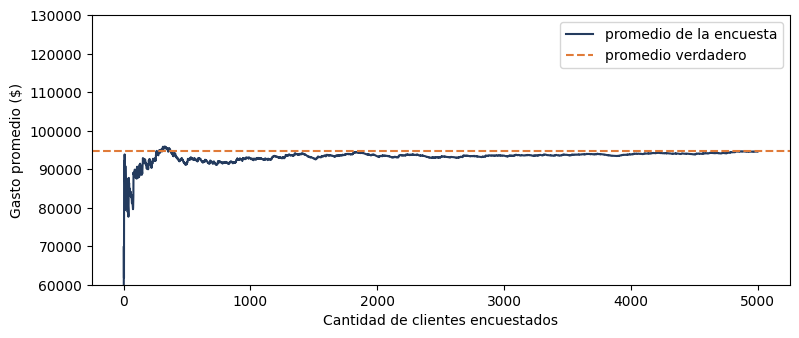

In [7]:
rng = np.random.default_rng(3)
encuesta = clientes["gasto"].sample(5000, random_state=rng)   # 5.000 clientes en orden al azar
promedio_hasta_ahora = encuesta.expanding().mean()            # promedio con 1, 2, 3, ... clientes

plt.figure(figsize=(9, 3.5))
plt.plot(range(1, 5001), promedio_hasta_ahora, color=AZUL, label="promedio de la encuesta")
plt.axhline(gasto_verdadero, color=NARANJA, ls="--", label="promedio verdadero")
plt.xlabel("Cantidad de clientes encuestados")
plt.ylabel("Gasto promedio ($)")
plt.ylim(60_000, 130_000)
plt.legend()
plt.show()

Con pocos clientes el promedio salta mucho; a medida que sumamos gente **se acerca a la verdad y se queda cerca**.
Pero fijate que pasar de 1.000 a 5.000 clientes casi no cambia nada: a partir de cierto punto, encuestar a más gente cuesta mucho y mejora poco. Por eso las encuestas serias de un país entero usan **unas 1.000 personas**... **siempre que se elijan al azar**.

### ¿Importa cómo elijo a quién encuestar?

Comparamos tres formas de elegir 200 clientes. Repetimos cada encuesta 500 veces para ver cómo se comporta:

| Forma | Cómo se elige | Ejemplo real |
|---|---|---|
| **Aleatoria** | cualquiera de los 100.000, al azar | un sorteo sobre la base completa de clientes |
| **Estratificada** | al azar *dentro de cada segmento*, respetando cuántos hay de cada uno | 60% Básico, 30% Medio, 10% Premium |
| **Por conveniencia** | solo los fáciles de encontrar: los de Online | una encuesta que mandamos por la app |

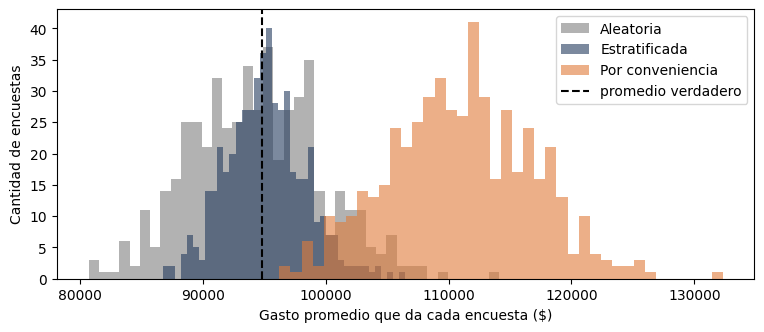

In [8]:
rng = np.random.default_rng(5)
online = clientes[clientes["canal"] == "Online"]

encuestas = {"Aleatoria": [], "Estratificada": [], "Por conveniencia": []}
for _ in range(500):
    encuestas["Aleatoria"].append(clientes.sample(200, random_state=rng)["gasto"].mean())
    encuestas["Estratificada"].append(clientes.groupby("segmento").sample(frac=0.002, random_state=rng)["gasto"].mean())
    encuestas["Por conveniencia"].append(online.sample(200, random_state=rng)["gasto"].mean())

plt.figure(figsize=(9, 3.5))
for forma, color in [("Aleatoria", "gray"), ("Estratificada", AZUL), ("Por conveniencia", NARANJA)]:
    plt.hist(encuestas[forma], bins=40, color=color, alpha=0.6, label=forma)
plt.axvline(gasto_verdadero, color="black", ls="--", label="promedio verdadero")
plt.xlabel("Gasto promedio que da cada encuesta ($)")
plt.ylabel("Cantidad de encuestas")
plt.legend()
plt.show()

In [9]:
for forma, resultados in encuestas.items():
    errores = np.array(resultados) - gasto_verdadero
    print(f"{forma:17}: cada encuesta se equivoca, en promedio, por $ {np.abs(errores).mean():>6,.0f}")

Aleatoria        : cada encuesta se equivoca, en promedio, por $  4,264
Estratificada    : cada encuesta se equivoca, en promedio, por $  2,468
Por conveniencia : cada encuesta se equivoca, en promedio, por $ 16,185


- **Aleatoria:** las encuestas caen alrededor de la verdad, a veces arriba y a veces abajo. Cada una se equivoca por unos **\$ 4.264**.
- **Estratificada:** también alrededor de la verdad, y **más juntas** (se equivocan por **\$ 2.468**). Al asegurar la cantidad justa de Premium, ninguna encuesta queda con demasiados o con muy pocos clientes que gastan mucho.
- **Por conveniencia:** **todas** se pasan para arriba, por unos **\$ 16.185**, porque los clientes de Online gastan más que el resto. Eso es un **sesgo**: un error que va siempre para el mismo lado.

### ¿Y si mandamos la encuesta por la app a mucha más gente?

In [10]:
rng = np.random.default_rng(6)

for n in [200, 2_000, 20_000]:
    error = online.sample(n, random_state=rng)["gasto"].mean() - gasto_verdadero
    print(f"Encuesta por la app a {n:>6,} clientes: se pasa por $ {error:,.0f}")

Encuesta por la app a    200 clientes: se pasa por $ 19,783
Encuesta por la app a  2,000 clientes: se pasa por $ 17,578
Encuesta por la app a 20,000 clientes: se pasa por $ 16,474


> **El sesgo no se arregla con más datos.** Con 20.000 respuestas el error sigue ahí: solo estamos más seguros de un número equivocado.
> Pasa con las encuestas por redes sociales, las reseñas online o "los clientes que se quejan". Antes de mirar cuántos datos hay, preguntate **quiénes** son.

---
# D. Simular para decidir: Monte Carlo

En un negocio, muchas cosas no se saben de antemano: cuánto se va a vender, cuánto van a rendir los flujos de un proyecto.
La **simulación de Monte Carlo** (por el casino) consiste en **simular miles de días o de futuros posibles** y elegir la decisión que mejor funciona en todos ellos.

### Caso 1: ¿cuántas medialunas hornear?

Una panadería vende cada medialuna a **\$500** y hacerla le cuesta **\$200**. Lo que sobra al final del día se tira.
La demanda cambia todos los días: en promedio piden **120**, a veces más y a veces menos.
- Si hornea **pocas**, se queda sin y pierde ventas.
- Si hornea **muchas**, le sobran y pierde lo que le costó hacerlas.

Simulamos **1.000 días** de demanda y probamos cada cantidad posible:

In [11]:
rng = np.random.default_rng(8)
PRECIO, COSTO = 500, 200
demanda = rng.poisson(120, size=1000)          # medialunas pedidas en 1.000 días simulados

def ganancia_promedio(hornear):
    vendidas = np.minimum(demanda, hornear)       # no se vende más de lo que se pide ni de lo que hay
    return (vendidas * PRECIO - hornear * COSTO).mean()

opciones  = range(90, 161)
ganancias = [ganancia_promedio(h) for h in opciones]
mejor = opciones[np.argmax(ganancias)]
print(f"Conviene hornear {mejor} medialunas: ganancia promedio de $ {max(ganancias):,.0f} por día")

Conviene hornear 122 medialunas: ganancia promedio de $ 34,018 por día


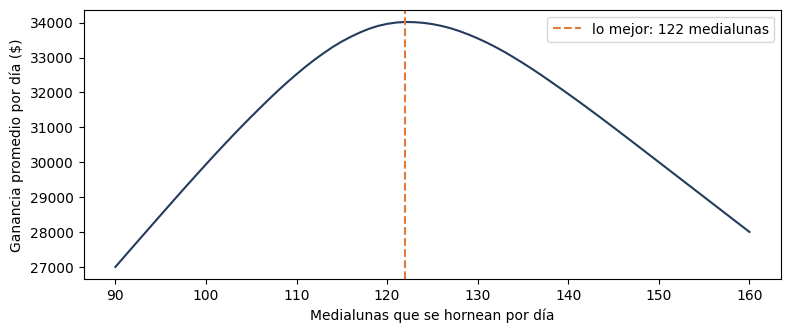

In [12]:
plt.figure(figsize=(9, 3.5))
plt.plot(opciones, ganancias, color=AZUL)
plt.axvline(mejor, color=NARANJA, ls="--", label=f"lo mejor: {mejor} medialunas")
plt.xlabel("Medialunas que se hornean por día")
plt.ylabel("Ganancia promedio por día ($)")
plt.legend()
plt.show()

Conviene hornear **122**, un poco **más** que el promedio de 120. ¿Por qué? Porque quedarse sin una medialuna cuesta \$300 (la venta perdida) y que sobre una cuesta solo \$200. Ante la duda, conviene pasarse un poco.
Esta cuenta no sale con una regla de tres: sale **probando en 1.000 días simulados**.

### Caso 2: ¿el horno de la clase 14 realmente conviene?

En la clase 14 evaluamos un horno que cuesta **\$10 millones** y deja flujos de **3 / 3,5 / 4 / 4 / 3 millones** en cinco años, con un costo de capital del **20%**.
El **VAN dio +0,38 millones**: conviene, pero por poco.

Esa cuenta supone que los flujos salen **exactos**. En la realidad pueden salir mejor o peor (digamos, un 20% para arriba o para abajo). Simulamos **20.000 futuros**:

In [13]:
rng = np.random.default_rng(7)

inversion = 10                              # millones de pesos
flujos    = np.array([3, 3.5, 4, 4, 3])     # años 1 a 5
descuento = 1.20 ** np.arange(1, 6)         # costo de capital del 20%
print(f"VAN con los flujos esperados: {(flujos / descuento).sum() - inversion:.2f} millones")

futuros = rng.normal(flujos, 0.20 * flujos, size=(20_000, 5))   # cada fila es un futuro posible
van     = (futuros / descuento).sum(axis=1) - inversion

print(f"VAN promedio de los futuros : {van.mean():.2f} millones")
print(f"Probabilidad de perder plata: {(van < 0).mean():.1%}")

VAN con los flujos esperados: 0.38 millones
VAN promedio de los futuros : 0.38 millones
Probabilidad de perder plata: 34.5%


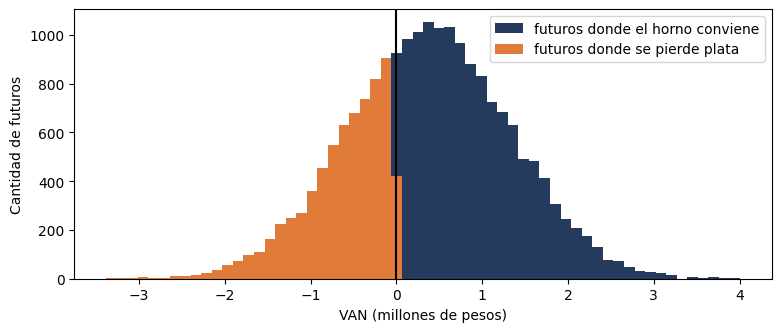

In [14]:
bordes = np.linspace(van.min(), van.max(), 61)        # las mismas barras para los dos colores

plt.figure(figsize=(9, 3.5))
plt.hist(van,          bins=bordes, color=AZUL,    label="futuros donde el horno conviene")
plt.hist(van[van < 0], bins=bordes, color=NARANJA, label="futuros donde se pierde plata")
plt.axvline(0, color="black")
plt.xlabel("VAN (millones de pesos)")
plt.ylabel("Cantidad de futuros")
plt.legend()
plt.show()

En promedio el horno sigue conviniendo, pero en el **34,5%** de los futuros hace perder plata: más o menos **una chance en tres**.
Un número solo ("VAN = +0,38") esconde ese riesgo; la simulación lo muestra. Con esa información, un gerente puede decidir distinto.

---
# Ejercicios

**Ejercicio 1 - Dos dados.** Simulá 100.000 tiradas de **dos dados**. ¿En qué porcentaje de las veces suman 7? Compará con la teoría: 6/36.

**Ejercicio 2 - Medialunas más caras.** Si hacer cada medialuna cuesta **\$350** en vez de \$200 (y se sigue vendiendo a \$500), ¿cuántas conviene hornear? ¿Más o menos que el promedio de 120? ¿Por qué?

**Ejercicio 3 - Un horno más incierto.** En el caso 2, ¿qué pasa con la probabilidad de perder plata si los flujos pueden variar un **30%** en vez de un 20%? ¿Cambia mucho el VAN promedio?

In [15]:
# Ejercicio 1 - tu respuesta acá

In [16]:
# Ejercicio 2 - tu respuesta acá

In [17]:
# Ejercicio 3 - tu respuesta acá

---
## Soluciones

Intentalo antes de mirar.

In [18]:
# Solución ejercicio 1
rng = np.random.default_rng(100)
suma = rng.integers(1, 7, 100_000) + rng.integers(1, 7, 100_000)
print(f"Simulación: {(suma == 7).mean():.1%}   Teoría: {6 / 36:.1%}")

Simulación: 16.7%   Teoría: 16.7%


In [19]:
# Solución ejercicio 2
COSTO = 350
ganancias = [ganancia_promedio(h) for h in opciones]
print("Ahora conviene hornear", opciones[np.argmax(ganancias)], "medialunas")
# Menos que el promedio: ahora que sobre una cuesta $350 y quedarse sin, solo $150 de ganancia perdida.
COSTO = 200   # volvemos al valor original

Ahora conviene hornear 115 medialunas


In [20]:
# Solución ejercicio 3
rng = np.random.default_rng(101)
futuros_30 = rng.normal(flujos, 0.30 * flujos, size=(20_000, 5))
van_30 = (futuros_30 / descuento).sum(axis=1) - inversion
print(f"VAN promedio: {van_30.mean():.2f} millones")
print(f"Probabilidad de perder plata: {(van_30 < 0).mean():.1%}")
# El VAN promedio casi no cambia, pero el riesgo de perder crece: más incertidumbre, más riesgo.

VAN promedio: 0.38 millones
Probabilidad de perder plata: 39.3%


---
## Para llevarse

| Situación | Qué hacer |
|---|---|
| Quiero resultados repetibles | fijar la semilla: `np.random.default_rng(42)` o `random_state=42` |
| No tengo datos (o son confidenciales) y quiero practicar | **simular** una base con la misma forma |
| Voy a sacar conclusiones de una muestra | que sea **al azar**; más datos ayudan, pero cada vez menos |
| Hay grupos muy distintos (como los Premium) | muestra **estratificada**, para que no queden afuera |
| Mis datos son "los que respondieron" | desconfiá: **el sesgo no se arregla con más datos** |
| Tengo que decidir sin saber qué va a pasar | **Monte Carlo**: simular miles de días o futuros y comparar |

**En el TP:** digan siempre **de dónde salieron los datos** (¿toda la población o una muestra? ¿quién respondió?). Y si el análisis depende de supuestos inciertos, simulen escenarios en vez de mostrar un solo número.